# Evaluering av FlowerNet

Laster den lagrede modellen fra `models/flowernet.pt` og lager figurene til rapporten (kapittel 3, *Feilanalyse*).
Alle figurer lagres i `reports/figures/`. Notebooken trener ingenting, så den kan kjøres på nytt når som helst.

In [1]:
import sys; sys.path.append("..")
import torch
import matplotlib.pyplot as plt

from src.utils import get_device, set_seed
from src.model import load_model
from src.data import get_dataloaders, LABELS_CSV
from src.visualize import (get_predictions, summary_metrics, print_report, plot_class_distribution,
                           plot_history, plot_confusion, plot_per_class_accuracy, top_confusions,
                           plot_wrong, plot_grad_cam, plot_calibration, plot_tsne)

set_seed()
device = get_device()
print(device, torch.cuda.get_device_name(device) if device.type == "cuda" else "")

model, ckpt = load_model(device=device)
classes = ckpt["classes"]
train_dataloader, val_dataloader, test_dataloader = get_dataloaders(batch_size=64)
test_data = test_dataloader.dataset
print(f"{len(classes)} klasser, {len(test_data)} testbilder, lagret test acc {ckpt['test_acc']:.1%}")

cuda:0 AMD Radeon RX 9070 XT
19 klasser, 2585 testbilder, lagret test acc 66.3%


## 1. Data: klassefordeling

Viser at lavender, lotus og orchid har omtrent halvparten så mange bilder som de andre artene.

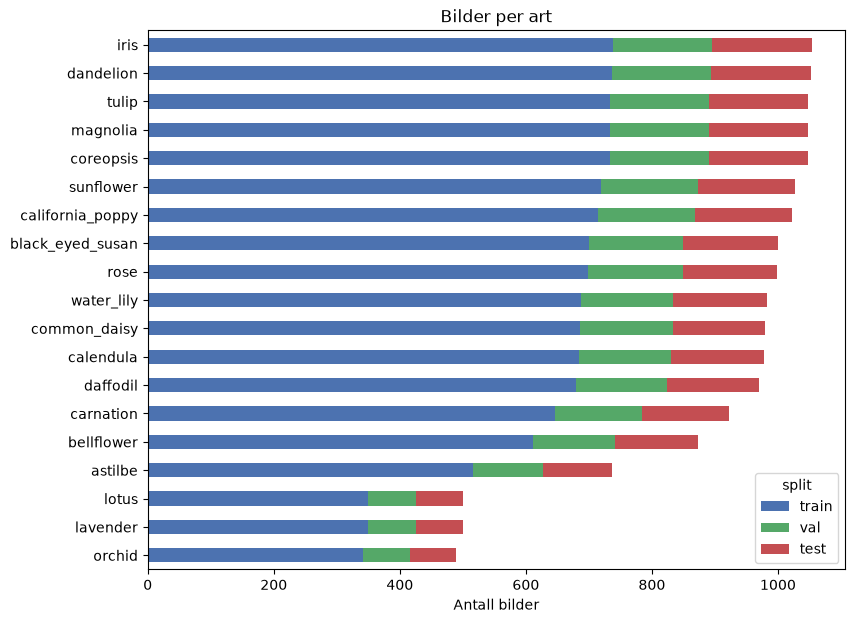

In [2]:
plot_class_distribution(LABELS_CSV, classes); plt.show()

## 2. Treningskurver

Hvis train-kurven fortsetter oppover mens val-kurven flater ut eller går ned, overtilpasser modellen. Ligger kurvene tett og stiger fortsatt, er det underfitting.

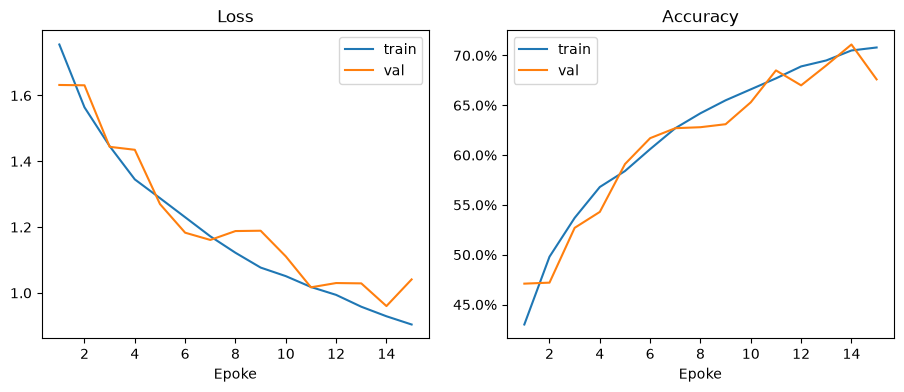

In [3]:
plot_history(ckpt["history"]); plt.show()

## 3. Metrikker på testsettet

Accuracy, macro-F1 og top-3/top-5, som definert i rapporten (kapittel 1, *Metrikker*).

In [4]:
y_true, y_pred, y_prob = get_predictions(model, test_dataloader, device)

for k, v in summary_metrics(y_true, y_pred, y_prob).items():
    print(f"{k:>9}: {v:.1%}")
print()
print_report(y_true, y_pred, classes)

 accuracy: 66.3%
 macro_f1: 64.8%
     top3: 89.4%
     top5: 95.0%

                  precision    recall  f1-score   support

         astilbe      0.497     0.791     0.611       110
      bellflower      0.843     0.328     0.473       131
black_eyed_susan      0.860     0.740     0.796       150
       calendula      0.742     0.449     0.559       147
california_poppy      0.673     0.682     0.677       154
       carnation      0.511     0.522     0.516       138
    common_daisy      0.766     0.755     0.760       147
       coreopsis      0.786     0.631     0.700       157
        daffodil      0.957     0.603     0.739       146
       dandelion      0.751     0.880     0.810       158
            iris      0.684     0.766     0.722       158
        lavender      0.573     0.627     0.599        75
           lotus      0.729     0.467     0.569        75
        magnolia      0.590     0.752     0.661       157
          orchid      0.256     0.630     0.364        73
  

## 4. Confusion matrix: hvilke arter forveksles?

Diagonalen viser andelen riktige per art (recall). Celler utenfor diagonalen er forvekslinger.

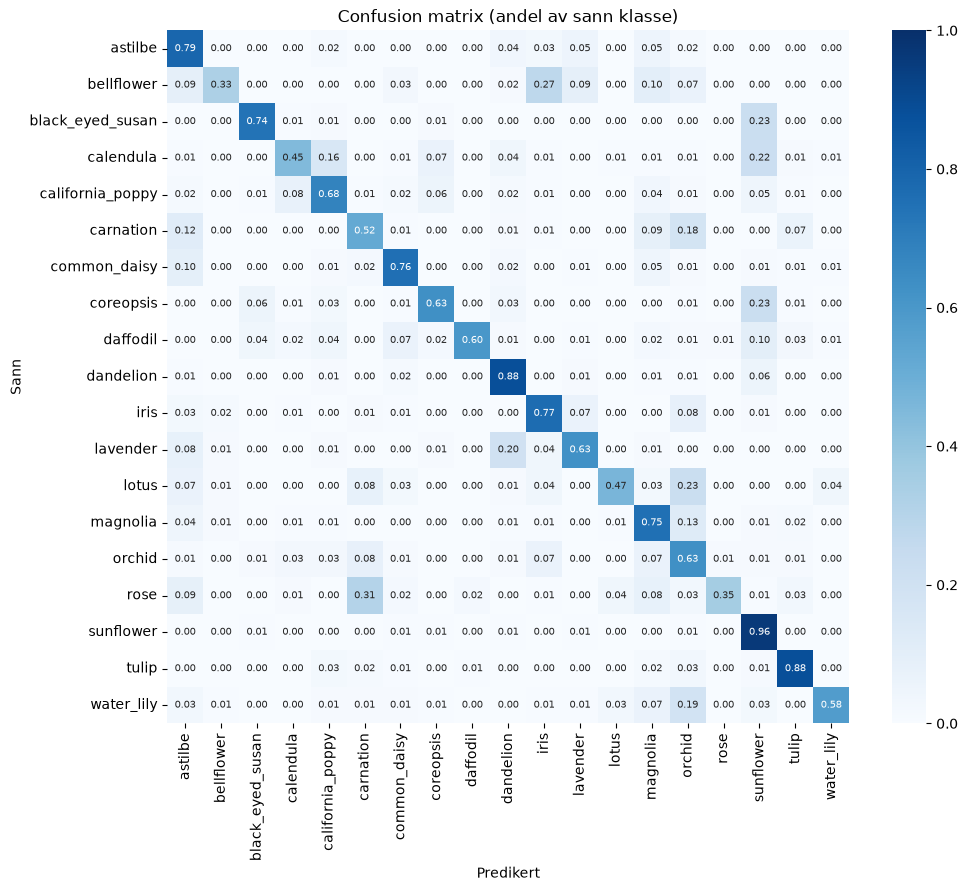

In [5]:
plot_confusion(y_true, y_pred, classes); plt.show()

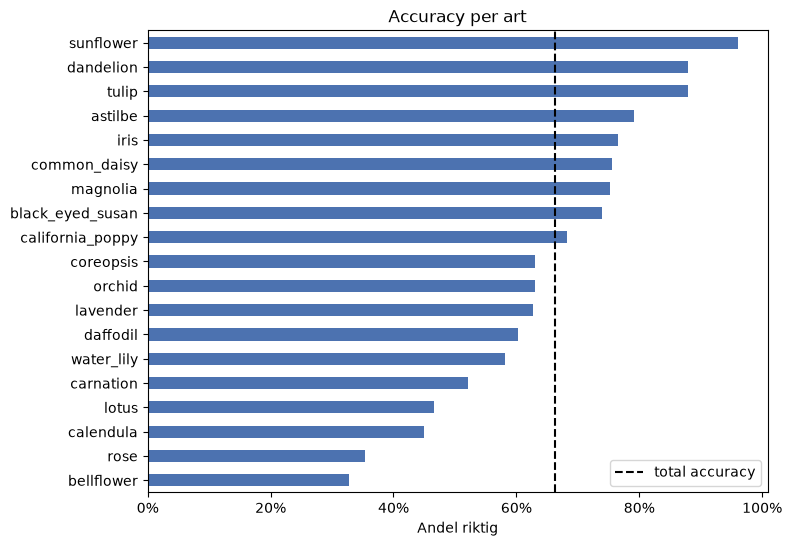

,sann,predikert,antall
0,rose,carnation,46
1,bellflower,iris,36
2,coreopsis,sunflower,36
3,black_eyed_susan,sunflower,34
4,calendula,sunflower,33
5,water_lily,orchid,28
6,carnation,orchid,25
7,calendula,california_poppy,23
8,magnolia,orchid,20
9,lotus,orchid,17


In [6]:
plot_per_class_accuracy(y_true, y_pred, classes); plt.show()
top_confusions(y_true, y_pred, classes, n=10)

## 5. Feilklassifiserte bilder

De feilene modellen var mest sikker på. Se etter mønstre: feil label, flere blomster i bildet, dårlig lys, liten blomst.

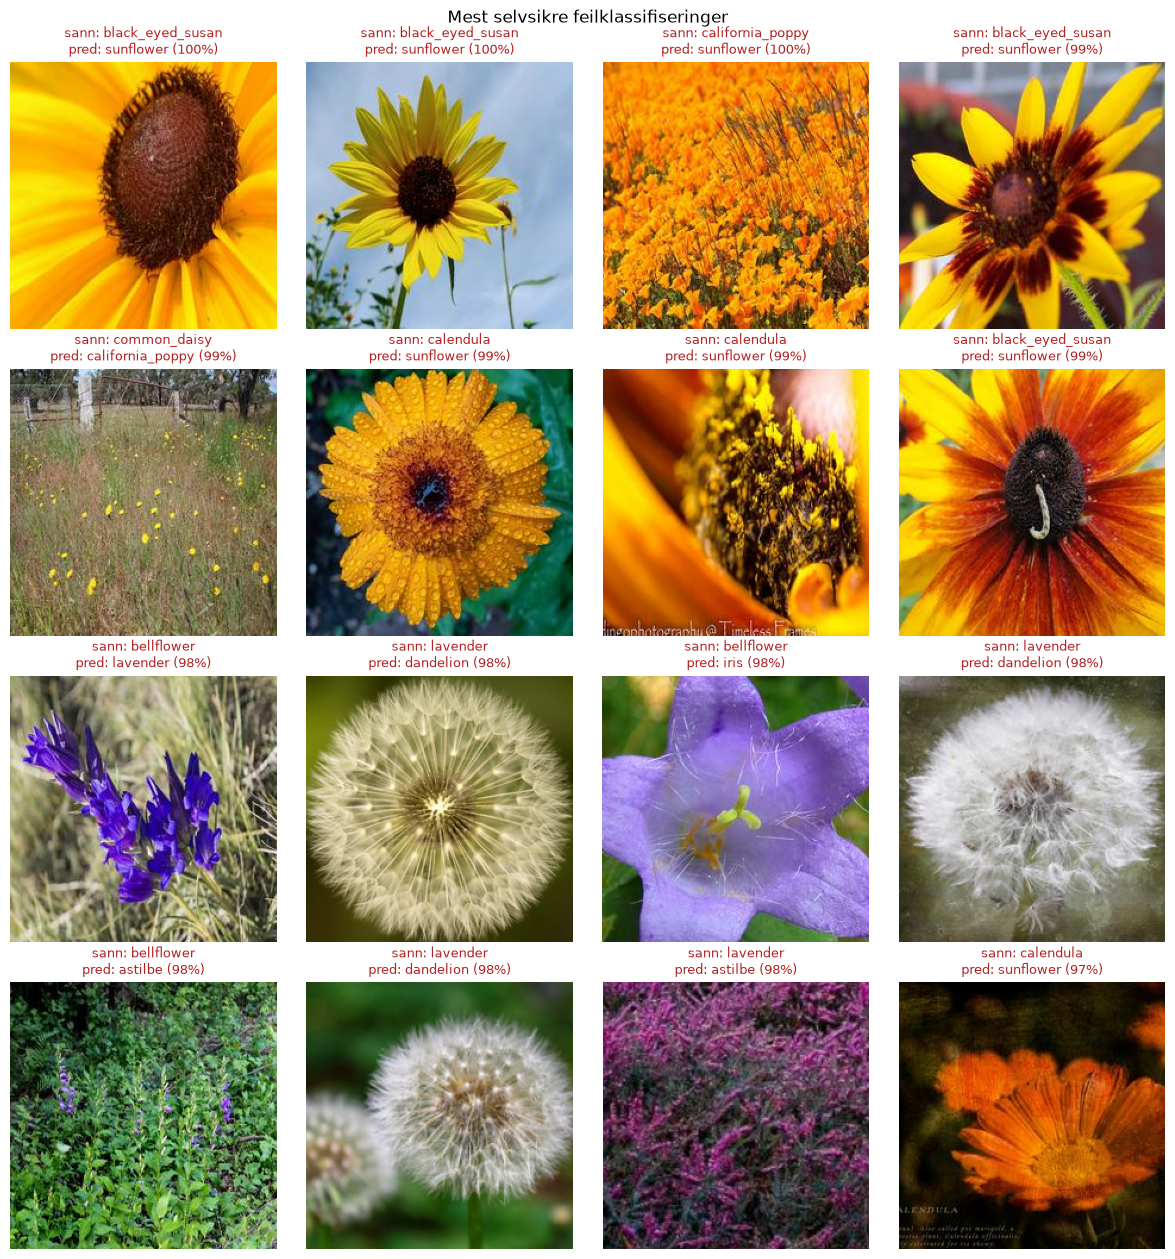

In [7]:
plot_wrong(test_data, y_true, y_pred, y_prob, classes, n=16); plt.show()

## 6. Grad-CAM: hvor i bildet ser modellen?

Rødt viser områdene som påvirket prediksjonen mest. Øverst: tilfeldige testbilder. Nederst: feilklassifiserte. Ser modellen på blomsten eller på bakgrunnen?

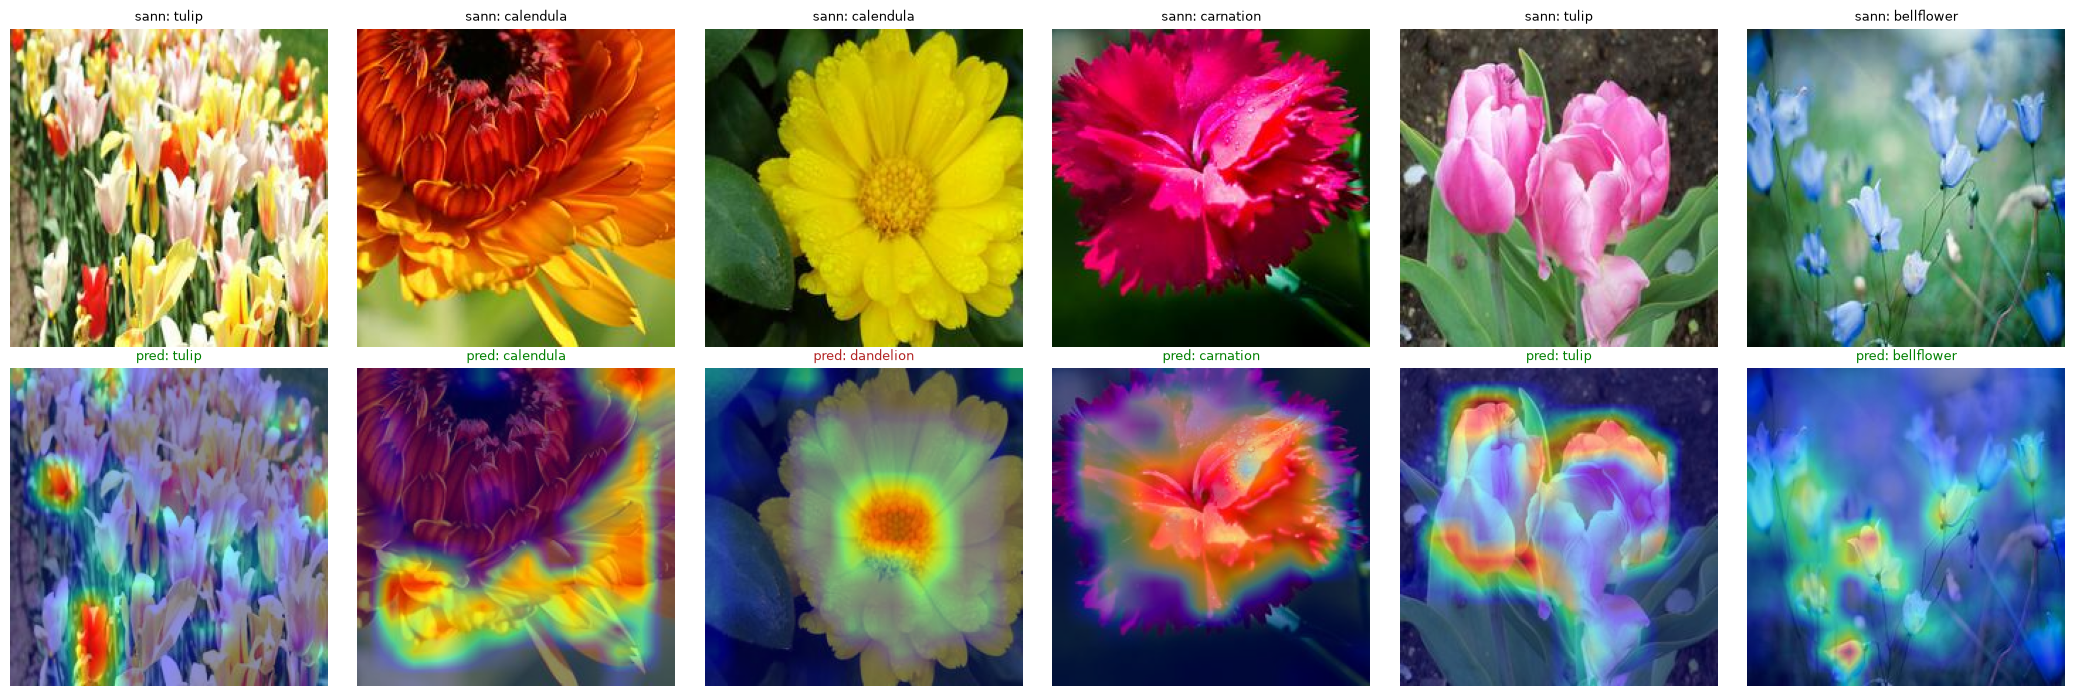

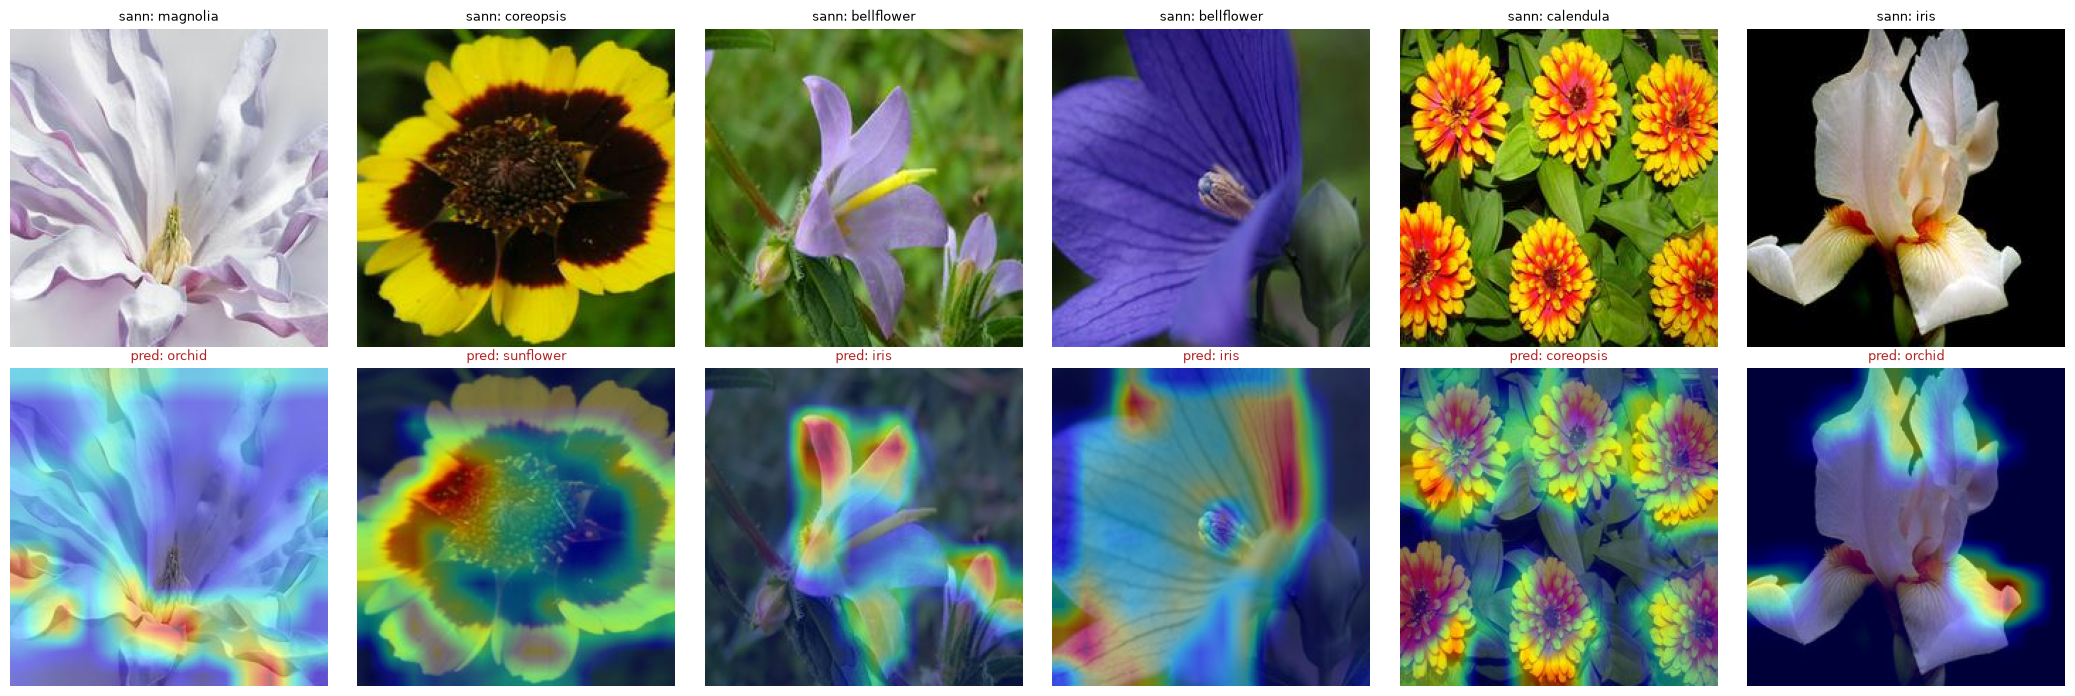

In [8]:
g = torch.Generator().manual_seed(42)
plot_grad_cam(model, test_data, classes, device, torch.randperm(len(test_data), generator=g)[:6].tolist(), name="grad_cam_tilfeldige"); plt.show()

wrong = (y_pred != y_true).nonzero().flatten()
plot_grad_cam(model, test_data, classes, device, wrong[torch.randperm(len(wrong), generator=g)[:6]].tolist(), name="grad_cam_feil"); plt.show()

## 7. Kalibrering

Når modellen sier 80 % sikker, har den rett 80 % av gangene? Viktig for terskelen «Usikker, prøv et nytt bilde» i appen. ECE er gjennomsnittlig avvik (lavere er bedre).

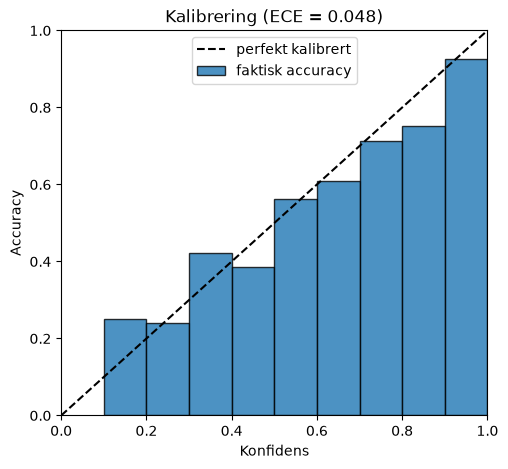

In [9]:
plot_calibration(y_true, y_prob); plt.show()

## 8. t-SNE av features

De 256 featurene modellen bruker til å klassifisere, redusert til 2D. Klasser som ligger i egne grupper er lette å skille, og klasser som overlapper forveksles.

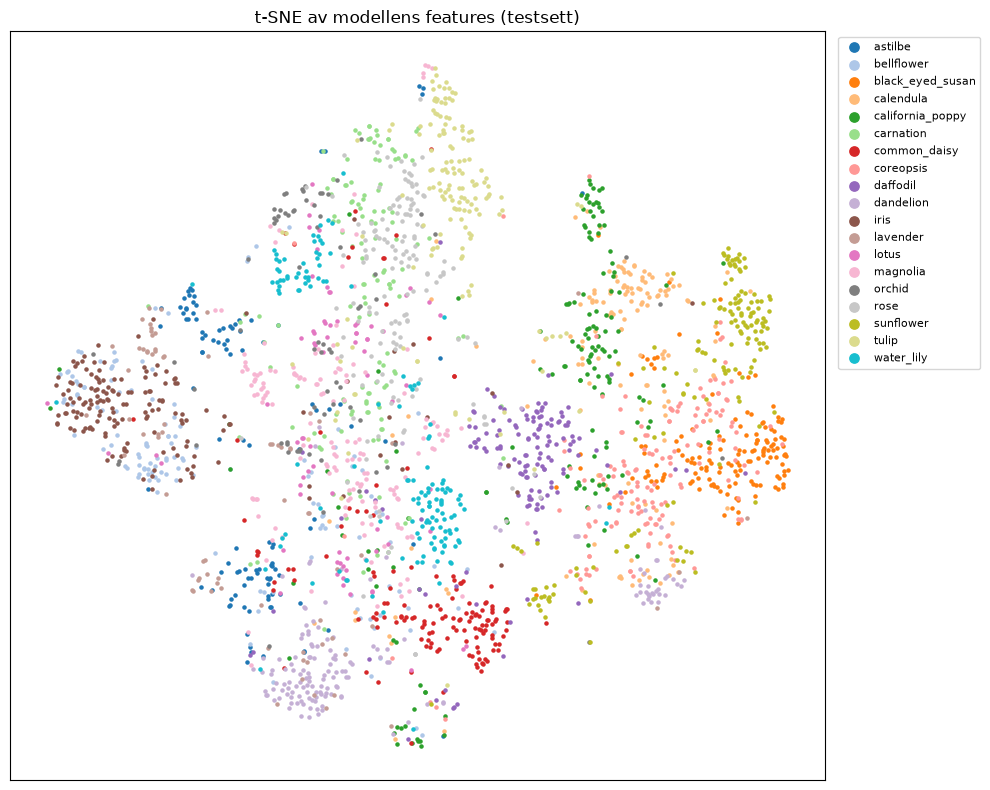

In [10]:
plot_tsne(model, test_dataloader, classes, device); plt.show()